# 06 - Validation

Evaluates every model (default and tuned) on the held-out test set and compares them.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set(style="darkgrid")

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [2]:
X_test = pd.read_csv('data/processed/X_test.csv')
y_test = pd.read_csv('data/processed/y_test.csv')['spend_next_month']
scaler = joblib.load('models/scaler.pkl')
X_test_sc = scaler.transform(X_test)

### Test Set Results

In [3]:
# model name: (file, needs scaling?)
models = {
    'Linear Regression':      ('linear_regression.pkl', True),
    'Random Forest':          ('random_forest.pkl', False),
    'XGBoost':                ('xgboost.pkl', False),
    'ANN':                    ('ann.pkl', True),
    'Random Forest (Optuna)': ('random_forest_optuna.pkl', False),
    'XGBoost (Optuna)':       ('xgboost_optuna.pkl', False),
    'ANN (Optuna)':           ('ann_optuna.pkl', True),
}

results = []
for name, (file, scaled) in models.items():
    model = joblib.load(f'models/{file}')
    pred = model.predict(X_test_sc if scaled else X_test)
    results.append([name,
                    mean_absolute_error(y_test, pred),
                    np.sqrt(mean_squared_error(y_test, pred)),
                    r2_score(y_test, pred)])

results_df = pd.DataFrame(results, columns=['Model', 'MAE', 'RMSE', 'R2']).sort_values('MAE').reset_index(drop=True)
results_df

,Model,MAE,RMSE,R2
0,XGBoost (Optuna),102.089444,158.391181,0.836611
1,Random Forest (Optuna),103.172018,159.761873,0.833771
2,ANN (Optuna),104.176612,158.881189,0.835599
3,Random Forest,104.234649,159.974723,0.833328
4,ANN,104.425156,158.559152,0.836265
5,XGBoost,107.544070,170.460201,0.810763
6,Linear Regression,116.532479,181.410440,0.785669


### Model Comparison

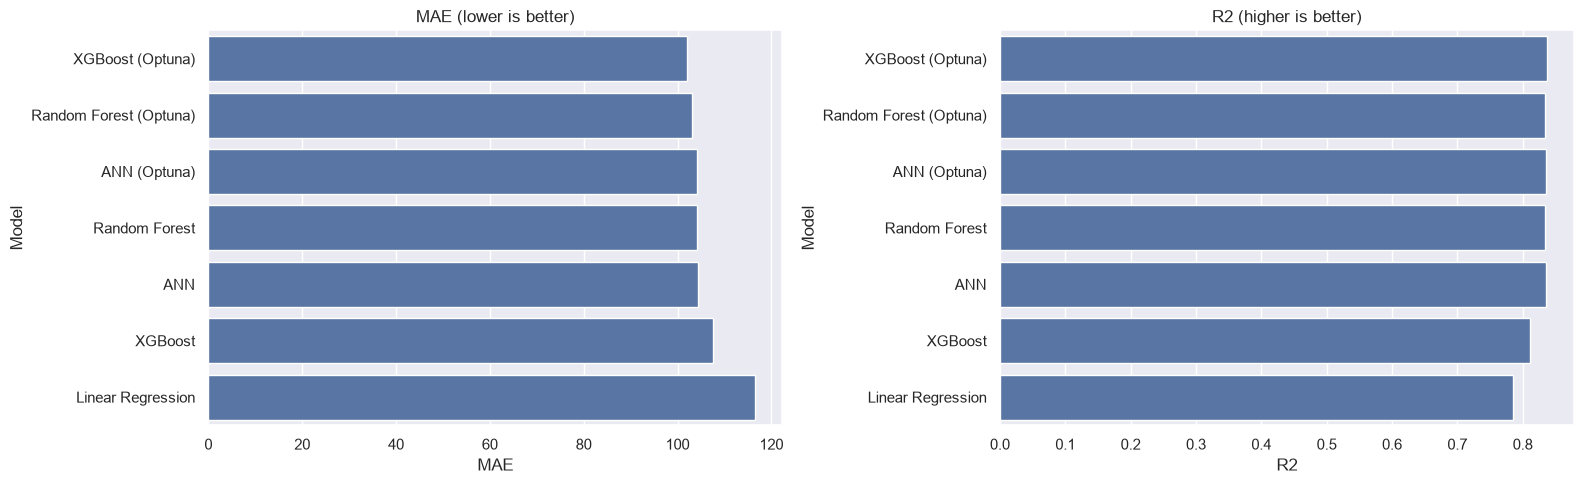

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16,5))
sns.barplot(data=results_df, y='Model', x='MAE', ax=axes[0])
axes[0].set_title('MAE (lower is better)')
sns.barplot(data=results_df, y='Model', x='R2', ax=axes[1])
axes[1].set_title('R2 (higher is better)')
plt.tight_layout()
plt.show()